# Blade convergence study: time, displacement accuracy and strain energy

Results only. Reference: **QuESo 256³**. The next cell loads the retained timing and displacement-error tables and draws the three summary graphs; the energy study follows, then the blade mesh.

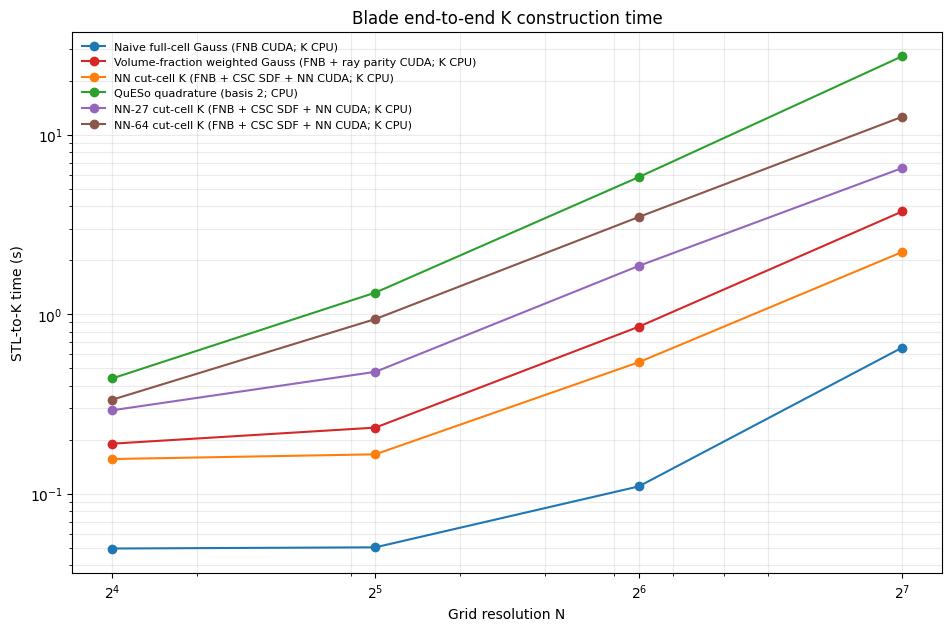

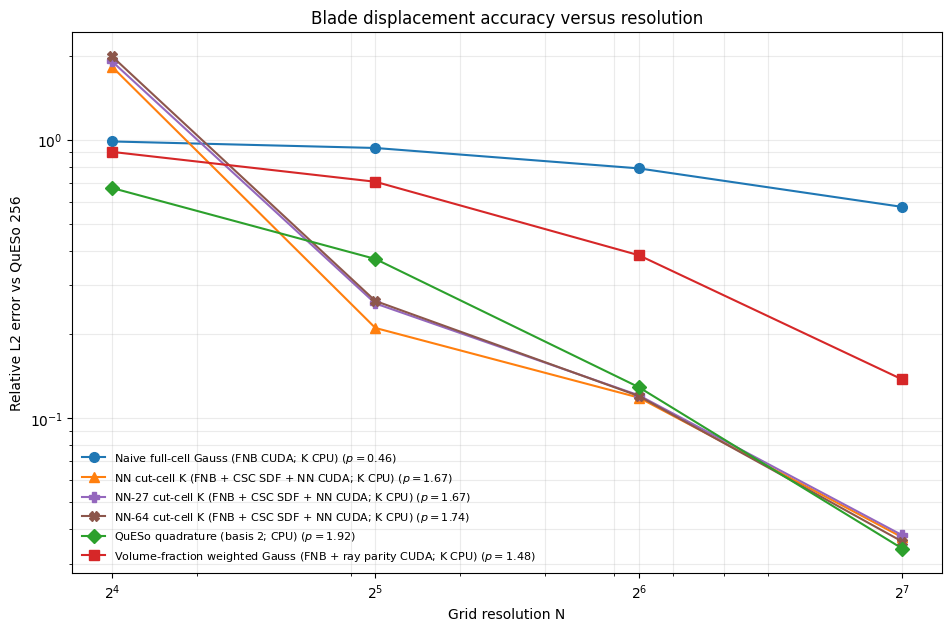

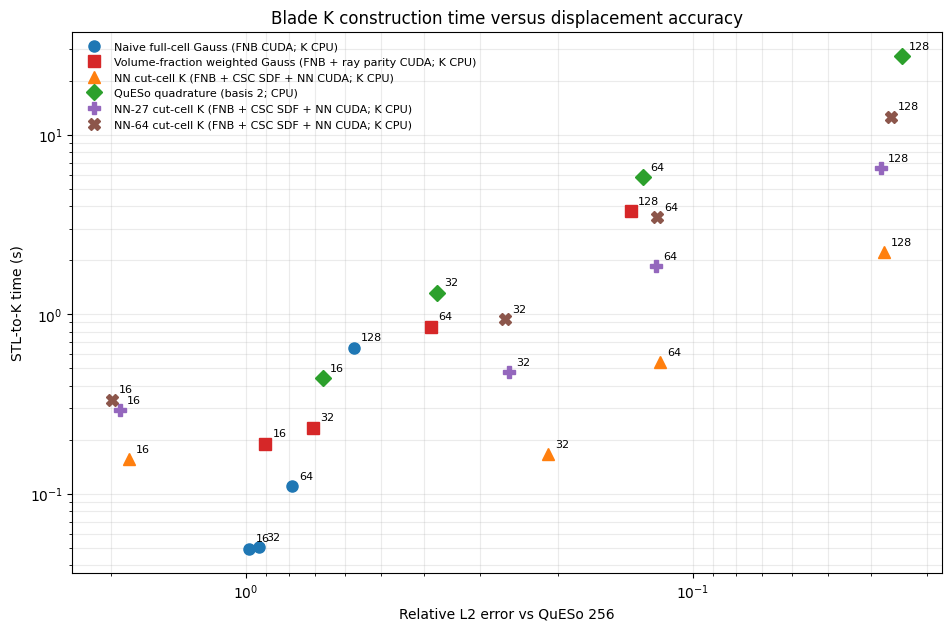

,variant,resolution,stl_load_seconds,grid_geometry_setup_seconds,fnb_total_seconds,fnb_candidate_generation_seconds,fnb_intersection_seconds,fnb_flood_fill_seconds,weighted_volume_fraction_seconds,nn_sdf_seconds,...,k_representation_assembly_seconds,end_to_end_k_seconds,unattributed_seconds,active_cells,cut_cells,weighted_samples_per_axis,nn_global_watertight_sign,queso_basis_order,nn_inference_device,nn_refined_subcells
0,naive_fnb,16,0.007070,0.000263,0.039790,0.029381,0.009513,0.000188,0.000000,0.000000,...,0.000749,0.049554,0.000849,352,340,0,False,0,not_applicable,NaN
20,nn_27_fnb,16,0.020707,0.000411,0.038866,0.029174,0.008748,0.000220,0.000000,0.210471,...,0.001999,0.291641,0.000856,352,340,0,True,0,cuda,2.0
21,nn_64_fnb,16,0.041630,0.000312,0.039197,0.030485,0.007763,0.000215,0.000000,0.227071,...,0.000932,0.333886,0.000849,352,340,0,True,0,cuda,3.0
2,nn_fnb,16,0.006710,0.000320,0.036246,0.029466,0.005814,0.000225,0.000000,0.099715,...,0.002097,0.156144,0.000869,352,340,0,True,0,cuda,NaN
3,queso_p2,16,0.006296,0.000303,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.438723,0.001015,335,323,0,False,2,not_applicable,NaN
1,weighted_fnb,16,0.006442,0.000255,0.040934,0.031183,0.008854,0.000177,0.140546,0.000000,...,0.000724,0.190094,0.000810,352,340,4,False,0,not_applicable,NaN
5,naive_fnb,32,0.006214,0.000352,0.038678,0.032124,0.005000,0.000826,0.000000,0.000000,...,0.003566,0.050311,0.000856,1759,1490,0,False,0,not_applicable,NaN
22,nn_27_fnb,32,0.018394,0.000374,0.044334,0.032520,0.010125,0.000854,0.000000,0.360012,...,0.006990,0.477785,0.000994,1759,1490,0,True,0,cuda,2.0
23,nn_64_fnb,32,0.043341,0.000431,0.043290,0.032433,0.009226,0.000849,0.000000,0.737199,...,0.007157,0.940184,0.000932,1759,1490,0,True,0,cuda,3.0
7,nn_fnb,32,0.006613,0.000320,0.039842,0.032496,0.005786,0.000834,0.000000,0.096635,...,0.002338,0.165877,0.000853,1759,1490,0,True,0,cuda,NaN


,variant,resolution,stl_load_seconds,grid_geometry_setup_seconds,fnb_total_seconds,fnb_candidate_generation_seconds,fnb_intersection_seconds,fnb_flood_fill_seconds,weighted_volume_fraction_seconds,nn_sdf_seconds,...,unattributed_seconds,active_cells,cut_cells,weighted_samples_per_axis,nn_global_watertight_sign,queso_basis_order,nn_inference_device,nn_refined_subcells,framework,relative_l2_error
0,naive_fnb,16,0.007070,0.000263,0.039790,0.029381,0.009513,0.000188,0.000000,0.000000,...,0.000849,352,340,0,False,0,not_applicable,NaN,naive,0.985832
4,naive_fnb,32,0.006214,0.000352,0.038678,0.032124,0.005000,0.000826,0.000000,0.000000,...,0.000856,1759,1490,0,False,0,not_applicable,NaN,naive,0.934056
8,naive_fnb,64,0.006632,0.001762,0.054435,0.035463,0.011381,0.006582,0.000000,0.000000,...,0.001580,10400,6579,0,False,0,not_applicable,NaN,naive,0.789067
12,naive_fnb,128,0.006855,0.020706,0.139746,0.054149,0.031122,0.052550,0.000000,0.000000,...,0.004215,69063,26911,0,False,0,not_applicable,NaN,naive,0.573880
16,nn_27_fnb,16,0.020707,0.000411,0.038866,0.029174,0.008748,0.000220,0.000000,0.210471,...,0.000856,352,340,0,True,0,cuda,2.0,nn_27,1.911913
18,nn_27_fnb,32,0.018394,0.000374,0.044334,0.032520,0.010125,0.000854,0.000000,0.360012,...,0.000994,1759,1490,0,True,0,cuda,2.0,nn_27,0.258280
20,nn_27_fnb,64,0.020521,0.001381,0.056325,0.037351,0.011531,0.006504,0.000000,1.482033,...,0.001447,10400,6579,0,True,0,cuda,2.0,nn_27,0.120858
22,nn_27_fnb,128,0.018217,0.023057,0.141613,0.054601,0.032331,0.053119,0.000000,4.929323,...,0.003513,69063,26911,0,True,0,cuda,2.0,nn_27,0.038024
17,nn_64_fnb,16,0.041630,0.000312,0.039197,0.030485,0.007763,0.000215,0.000000,0.227071,...,0.000849,352,340,0,True,0,cuda,3.0,nn_64,1.993535
19,nn_64_fnb,32,0.043341,0.000431,0.043290,0.032433,0.009226,0.000849,0.000000,0.737199,...,0.000932,1759,1490,0,True,0,cuda,3.0,nn_64,0.263646


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator, NullFormatter

_root_candidates = (Path.cwd(), *Path.cwd().parents)
_configured_root = globals().get("ROOT")
ROOT = (
    _configured_root
    if _configured_root is not None and (_configured_root / "clean_simulation").is_dir()
    else next(candidate for candidate in _root_candidates if (candidate / "clean_simulation").is_dir())
)
BLADE_FINAL_TIMING_DIR = (
    ROOT / "clean_simulation" / "outputs" / "studies" / "blade" / "end_to_end_k_timing"
    / "aws_blade_end_to_end_k_timing_v6_cuda_fnb_warm"
)
BLADE_FINAL_TIMING_CSV = BLADE_FINAL_TIMING_DIR / "blade_end_to_end_k_timing.csv"
BLADE_RICH_TIMING_DIR = ROOT / "clean_simulation" / "outputs" / "aws_blade_end_to_end_k_timing_v7_nn27_nn64"
BLADE_RICH_TIMING_CSV = BLADE_RICH_TIMING_DIR / "blade_end_to_end_k_timing.csv"
BLADE_RETAINED_ERROR_CSV = ROOT / "clean_simulation" / "notebooks" / "aws_blade_convergence_v2" / "blade_displacement_l2_vs_queso_256.csv"

METHOD_LABELS = {
    "naive_fnb": "Naive full-cell Gauss (FNB CUDA; K CPU)",
    "weighted_fnb": "Volume-fraction weighted Gauss (FNB + ray parity CUDA; K CPU)",
    "nn_fnb": "NN cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "nn_27_fnb": "NN-27 cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "nn_64_fnb": "NN-64 cut-cell K (FNB + CSC SDF + NN CUDA; K CPU)",
    "queso_p2": "QuESo quadrature (basis 2; CPU)",
}
METHOD_COLORS = {
    "naive_fnb": "#1f77b4",
    "weighted_fnb": "#d62728",
    "nn_fnb": "#ff7f0e",
    "nn_27_fnb": "#9467bd",
    "nn_64_fnb": "#8c564b",
    "queso_p2": "#2ca02c",
}
METHOD_MARKERS = {
    "naive_fnb": "o",
    "weighted_fnb": "s",
    "nn_fnb": "^",
    "nn_27_fnb": "P",
    "nn_64_fnb": "X",
    "queso_p2": "D",
}
ERROR_FRAMEWORKS = {
    "naive_fnb": "naive",
    "weighted_fnb": "weighted",
    "nn_fnb": "nn",
    "nn_27_fnb": "nn_27",
    "nn_64_fnb": "nn_64",
    "queso_p2": "queso",
}

required_artifacts = (BLADE_FINAL_TIMING_CSV, BLADE_RICH_TIMING_CSV, BLADE_RETAINED_ERROR_CSV)
missing = [str(path) for path in required_artifacts if not path.is_file()]
if missing:
    raise FileNotFoundError("Pull the original and rich-SDF Blade result tables first:\n" + "\n".join(missing))

blade_final_timing = pd.concat(
    (pd.read_csv(BLADE_FINAL_TIMING_CSV), pd.read_csv(BLADE_RICH_TIMING_CSV)),
    ignore_index=True,
)
blade_final_timing = blade_final_timing[blade_final_timing["variant"].isin(METHOD_LABELS)].copy()
blade_final_timing["resolution"] = blade_final_timing["resolution"].astype(int)
if blade_final_timing.duplicated(["variant", "resolution"]).any():
    raise ValueError("Combined timing tables contain duplicate method-resolution rows.")
retained_errors = pd.read_csv(BLADE_RETAINED_ERROR_CSV)
accuracy_variants = pd.DataFrame({
    "variant": list(ERROR_FRAMEWORKS),
    "framework": list(ERROR_FRAMEWORKS.values()),
})
accuracy_by_resolution = retained_errors.merge(
    accuracy_variants,
    on="framework",
    how="inner",
    validate="many_to_one",
)

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in blade_final_timing.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    axis.loglog(
        curve["resolution"], curve["end_to_end_k_seconds"], "o-",
        color=METHOD_COLORS[variant], label=METHOD_LABELS[variant],
    )
axis.set(
    xlabel="Grid resolution N",
    ylabel="STL-to-K time (s)",
    title="Blade end-to-end K construction time",
)
axis.xaxis.set_major_locator(FixedLocator([16, 32, 64, 128]))
axis.xaxis.set_major_formatter(FixedFormatter([r"$2^4$", r"$2^5$", r"$2^6$", r"$2^7$"]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in accuracy_by_resolution.groupby("variant", sort=False):
    curve = curve.sort_values("resolution")
    previous, final = curve.iloc[-2], curve.iloc[-1]
    observed_order = np.log(previous["relative_l2_error"] / final["relative_l2_error"]) / np.log(
        final["resolution"] / previous["resolution"]
    )
    axis.loglog(
        curve["resolution"], curve["relative_l2_error"],
        linestyle="-", marker=METHOD_MARKERS[variant], markersize=7,
        color=METHOD_COLORS[variant],
        label=fr"{METHOD_LABELS[variant]} ($p={observed_order:.2f}$)",
    )
axis.set(
    xlabel="Grid resolution N",
    ylabel="Relative L2 error vs QuESo 256",
    title="Blade displacement accuracy versus resolution",
)
accuracy_resolutions = sorted(accuracy_by_resolution["resolution"].unique())
axis.xaxis.set_major_locator(FixedLocator(accuracy_resolutions))
axis.xaxis.set_major_formatter(FixedFormatter([fr"$2^{{{int(value).bit_length() - 1}}}$" for value in accuracy_resolutions]))
axis.xaxis.set_minor_formatter(NullFormatter())
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

blade_time_accuracy = blade_final_timing.copy()
blade_time_accuracy["framework"] = blade_time_accuracy["variant"].map(ERROR_FRAMEWORKS)
blade_time_accuracy = blade_time_accuracy.merge(
    retained_errors[["framework", "resolution", "relative_l2_error"]],
    on=["framework", "resolution"], how="inner", validate="one_to_one",
)

figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in blade_time_accuracy.groupby("variant", sort=False):
    curve = curve.sort_values("relative_l2_error", ascending=False)
    axis.loglog(
        curve["relative_l2_error"], curve["end_to_end_k_seconds"],
        linestyle="None", marker=METHOD_MARKERS[variant], markersize=8,
        color=METHOD_COLORS[variant], label=METHOD_LABELS[variant],
    )
    for point in curve.itertuples(index=False):
        axis.annotate(
            f"{point.resolution}",
            (point.relative_l2_error, point.end_to_end_k_seconds),
            xytext=(5, 5), textcoords="offset points", fontsize=8,
        )
axis.invert_xaxis()
axis.set(
    xlabel="Relative L2 error vs QuESo 256",
    ylabel="STL-to-K time (s)",
    title="Blade K construction time versus displacement accuracy",
)
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

display(blade_final_timing.sort_values(["resolution", "variant"]))
display(blade_time_accuracy.sort_values(["variant", "resolution"]))

## Strain-energy study

Energy is computed from the **saved displacement fields** (`u_nodes`), with no re-solve and no stiffness rebuild:

$$E_e = \tfrac12\,u_e^{\mathsf T} K_e\,u_e ,$$

with $K_e$ the full-cell Hex8 stiffness ($E=10^6$, $\nu=0.3$, cell size from the saved `mesh_bounds`). Each $N^3$ cell's energy is compared with the sum over the $(256/N)^3$ QuESo-256 child cells it contains.

**Scope.** Only *interior* cells are compared: cells whose children are all active in the reference, with one extra ring of such neighbours, so every cell is a genuine full cell and $E_e$ equals the solver's local $\tfrac12 u_e^{\mathsf T}K_eu_e$ for every method. Cut cells are excluded because the stored files contain neither the cut-cell $K_e$ nor the cut volume, and a full-cell footprint there carries an $O(h)$ bias that would swamp the convergence order. The column `all_cells_total_signed_rel_diff` shows that bias for reference. Differences between methods therefore come from their displacement fields.

Metrics, per framework and resolution: regional total energy difference $|E-E_{\mathrm{ref}}|/E_{\mathrm{ref}}$; energy-weighted local error $\sum_e|E_e-E_e^{\mathrm{ref}}|/\sum_e E_e^{\mathrm{ref}}$ (headline); median and p95 of the cellwise relative error. The fitted order $p$ in the legends uses the last two resolutions, as in the displacement plot.

In [ ]:
import re

import numpy as np
import pandas as pd

# ---- Edit if needed ---------------------------------------------------------
ENERGY_REFERENCE = ("queso", 256)        # (framework, resolution) used as reference
YOUNG_MODULUS = 1.0e6                    # from the runner's material override
POISSON_RATIO = 0.3
CUBE_PADDING = 0.10                      # cube_bounds() padding used by the runner
INTERIOR_MARGIN = 1                      # a coarse cell is "interior" if it and this many rings of neighbours are fully inside the reference support
CELLWISE_FLOOR_FRACTION = 1.0e-4         # cells with E_ref below this x mean(E_ref) are excluded from cellwise stats
ENERGY_CHUNK = 262_144
DISPLACEMENT_DIR_OVERRIDE = None         # e.g. Path(r"C:\...\aws_blade_convergence_v2\checkpoints")
# -----------------------------------------------------------------------------

BLADE_LOCAL_RESULTS = ROOT / "clean_simulation" / "notebooks" / "aws_blade_convergence_v2"
ENERGY_CSV = BLADE_LOCAL_RESULTS / "blade_energy_error_vs_queso_256.csv"
FIELD_PATTERN = re.compile(r"blade_(?P<framework>.+)_displacement_(?P<resolution>\d+)cubed\.npz$")


def find_displacement_files():
    if DISPLACEMENT_DIR_OVERRIDE is not None:
        candidates = (Path(DISPLACEMENT_DIR_OVERRIDE),)
    else:
        base = ROOT / "clean_simulation"
        candidates = (
            base / "notebooks" / "aws_blade_convergence_v2" / "checkpoints",
            base / "outputs" / "aws_blade_convergence_v2" / "checkpoints",
            base / "notebooks" / "aws_blade_convergence_v2",
        )
    for directory in candidates:
        if not directory.is_dir():
            continue
        files = {}
        for path in directory.glob("blade_*_displacement_*cubed.npz"):
            match = FIELD_PATTERN.match(path.name)
            if match:
                files[(match["framework"], int(match["resolution"]))] = path
        if files:
            return directory, files
    raise FileNotFoundError(
        "No blade displacement .npz files found. Pull the remote `checkpoints/` folder of "
        "aws_blade_convergence_v2 or set DISPLACEMENT_DIR_OVERRIDE. Looked in:\n"
        + "\n".join(f"  {c}" for c in candidates)
    )


def cube_bounds(mesh_bounds, padding_fraction=CUBE_PADDING):
    """Same cube construction as the blade runner."""
    mesh_bounds = np.asarray(mesh_bounds, dtype=np.float64)
    center = mesh_bounds.mean(axis=0)
    half_width = float(np.max(mesh_bounds[1] - mesh_bounds[0])) * (0.5 + padding_fraction)
    return np.array([center - half_width, center + half_width])


# Hex8 node order used by the runner: (0,0,0) (1,0,0) (1,1,0) (0,1,0) (0,0,1) (1,0,1) (1,1,1) (0,1,1)
_NODE_SIGNS = np.array([
    (-1, -1, -1), (1, -1, -1), (1, 1, -1), (-1, 1, -1),
    (-1, -1, 1), (1, -1, 1), (1, 1, 1), (-1, 1, 1),
], dtype=np.float64)


def hex8_stiffness(h, young=YOUNG_MODULUS, poisson=POISSON_RATIO):
    """Full-cell trilinear Hex8 stiffness (2x2x2 Gauss), node-major dofs, cell side h."""
    lam = young * poisson / ((1 + poisson) * (1 - 2 * poisson))
    mu = young / (2 * (1 + poisson))
    C = np.zeros((6, 6))
    C[:3, :3] = lam
    C[np.arange(3), np.arange(3)] = lam + 2 * mu
    C[3:, 3:] = np.eye(3) * mu
    K = np.zeros((24, 24))
    g = 1.0 / np.sqrt(3.0)
    det_j = (h / 2.0) ** 3
    for xi in (-g, g):
        for eta in (-g, g):
            for zeta in (-g, g):
                sx, sy, sz = _NODE_SIGNS.T
                dN = np.stack((
                    sx * (1 + sy * eta) * (1 + sz * zeta),
                    sy * (1 + sx * xi) * (1 + sz * zeta),
                    sz * (1 + sx * xi) * (1 + sy * eta),
                )) / 8.0 * (2.0 / h)
                B = np.zeros((6, 24))
                for n in range(8):
                    dx, dy, dz = dN[:, n]
                    B[0, 3 * n] = dx
                    B[1, 3 * n + 1] = dy
                    B[2, 3 * n + 2] = dz
                    B[3, 3 * n], B[3, 3 * n + 1] = dy, dx
                    B[4, 3 * n + 1], B[4, 3 * n + 2] = dz, dy
                    B[5, 3 * n], B[5, 3 * n + 2] = dz, dx
                K += B.T @ C @ B * det_j
    return K


def cell_indices(cells, resolution):
    cells = np.asarray(cells, dtype=np.int64)
    return cells // (resolution * resolution), (cells // resolution) % resolution, cells % resolution


def cell_energies(u_nodes, active_cells, resolution, K_full):
    """0.5 * u_e^T K_full u_e for every active cell (u_nodes is (n_nodes, 3))."""
    side = resolution + 1
    offsets = np.array([
        0, side * side, side * side + side, side,
        1, side * side + 1, side * side + side + 1, side + 1,
    ], dtype=np.int64)
    out = np.empty(len(active_cells), dtype=np.float64)
    for start in range(0, len(active_cells), ENERGY_CHUNK):
        i, j, k = cell_indices(active_cells[start:start + ENERGY_CHUNK], resolution)
        nodes = ((i * side + j) * side + k)[:, None] + offsets
        local = u_nodes[nodes].reshape(len(nodes), 24)
        out[start:start + len(nodes)] = 0.5 * ((local @ K_full) * local).sum(axis=1)
    return out


def erode_26(mask):
    """True where the cell and all 26 neighbours are True."""
    padded = np.pad(mask, 1, constant_values=False)
    n0, n1, n2 = mask.shape
    out = np.ones_like(mask)
    for a in range(3):
        for b in range(3):
            for c in range(3):
                out &= padded[a:a + n0, b:b + n1, c:c + n2]
    return out


def load_field(path, resolution):
    with np.load(path, allow_pickle=False) as archive:
        field = {
            "u": np.asarray(archive["u_nodes"], dtype=np.float64).reshape(-1, 3),
            "cells": np.asarray(archive["active_cells"], dtype=np.int64),
            "mesh_bounds": np.asarray(archive["mesh_bounds"], dtype=np.float64),
            "constrained": np.asarray(archive["constrained_nodes"], dtype=np.int64),
        }
    if len(field["u"]) != (resolution + 1) ** 3:
        raise ValueError(f"{path.name}: expected {(resolution + 1) ** 3} nodes, found {len(field['u'])}.")
    return field


# Self-check of the element matrix: rigid translation costs nothing, uniform strain matches 0.5*eps*C*eps*V.
_h = 0.37
_K = hex8_stiffness(_h)
_corner = (_NODE_SIGNS + 1) / 2 * _h
_strain = 1.0e-3
_u = np.zeros((8, 3)); _u[:, 0] = _strain * _corner[:, 0]
_lam = YOUNG_MODULUS * POISSON_RATIO / ((1 + POISSON_RATIO) * (1 - 2 * POISSON_RATIO))
_mu = YOUNG_MODULUS / (2 * (1 + POISSON_RATIO))
assert np.allclose(_K @ np.tile([1.0, 0.0, 0.0], 8), 0.0, atol=1e-6)
assert np.isclose(0.5 * _u.reshape(-1) @ _K @ _u.reshape(-1), 0.5 * (_lam + 2 * _mu) * _strain**2 * _h**3, rtol=1e-12)
print("Hex8 element matrix self-check passed.")

In [ ]:
displacement_dir, displacement_files = find_displacement_files()
ref_framework, ref_resolution = ENERGY_REFERENCE
if ENERGY_REFERENCE not in displacement_files:
    raise FileNotFoundError(f"Reference field {ENERGY_REFERENCE} not found in {displacement_dir}.")
print(f"Displacement fields: {displacement_dir}  ({len(displacement_files)} files)")

reference = load_field(displacement_files[ENERGY_REFERENCE], ref_resolution)
bounds = cube_bounds(reference["mesh_bounds"])
extent = float(bounds[1, 0] - bounds[0, 0])
ref_energy = cell_energies(reference["u"], reference["cells"], ref_resolution, hex8_stiffness(extent / ref_resolution))
ref_i, ref_j, ref_k = cell_indices(reference["cells"], ref_resolution)
ref_peak = np.abs(reference["u"]).max()
print(f"Reference {ref_framework} {ref_resolution}^3: {len(ref_energy):,} active cells, "
      f"total kinematic energy {ref_energy.sum():.6e}; "
      f"max |u| at constrained nodes / max |u| = {np.abs(reference['u'][reference['constrained']]).max() / ref_peak:.2e}")

rows = []
for resolution in sorted({n for (_, n) in displacement_files if n < ref_resolution}):
    if ref_resolution % resolution:
        raise ValueError(f"{resolution} does not divide the reference resolution {ref_resolution}.")
    ratio = ref_resolution // resolution
    cell_count = resolution ** 3
    parent = ((ref_i // ratio) * resolution + ref_j // ratio) * resolution + ref_k // ratio
    child_count = np.bincount(parent, minlength=cell_count)
    child_energy = np.bincount(parent, weights=ref_energy, minlength=cell_count)
    fully_active = (child_count == ratio ** 3).reshape(resolution, resolution, resolution)
    interior_grid = fully_active
    for _ in range(INTERIOR_MARGIN):
        interior_grid = erode_26(interior_grid)
    interior = interior_grid.reshape(-1)
    if not interior.any():
        print(f"{resolution}^3: no interior cells (geometry too thin for this grid) - skipped.")
        continue
    K_coarse = hex8_stiffness(extent / resolution)

    for framework in [fw for (fw, n) in displacement_files if n == resolution]:
        field = load_field(displacement_files[(framework, resolution)], resolution)
        coarse_energy = np.zeros(cell_count)
        active = np.zeros(cell_count, dtype=bool)
        coarse_energy[field["cells"]] = cell_energies(field["u"], field["cells"], resolution, K_coarse)
        active[field["cells"]] = True

        mask = interior & active
        e_h, e_r = coarse_energy[mask], child_energy[mask]
        valid = e_r > CELLWISE_FLOOR_FRACTION * e_r.mean()
        cellwise = np.abs(e_h[valid] - e_r[valid]) / e_r[valid]
        footprint = active & (child_count > 0)
        rows.append({
            "framework": framework,
            "resolution": resolution,
            "interior_cells": int(mask.sum()),
            "cells_below_floor": int((~valid).sum()),
            "energy_total_signed_rel_diff": (e_h.sum() - e_r.sum()) / e_r.sum(),
            "energy_total_abs_rel_diff": abs(e_h.sum() - e_r.sum()) / e_r.sum(),
            "energy_l1_error": np.abs(e_h - e_r).sum() / e_r.sum(),
            "cellwise_median": float(np.median(cellwise)),
            "cellwise_p95": float(np.quantile(cellwise, 0.95)),
            "all_cells_total_signed_rel_diff": (coarse_energy[footprint].sum() - child_energy[footprint].sum()) / child_energy[footprint].sum(),
            "constrained_u_over_peak": float(np.abs(field["u"][field["constrained"]]).max() / np.abs(field["u"]).max()),
        })
        del field, coarse_energy
    print(f"{resolution}^3 done: {int(interior.sum()):,} interior cells.")

energy_metrics = pd.DataFrame(rows)
BLADE_LOCAL_RESULTS.mkdir(parents=True, exist_ok=True)
energy_metrics.to_csv(ENERGY_CSV, index=False)
print(f"Saved {ENERGY_CSV}")

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator, NullFormatter

if "energy_metrics" not in globals():
    energy_metrics = pd.read_csv(ENERGY_CSV)
FRAMEWORK_TO_VARIANT = {framework: variant for variant, framework in ERROR_FRAMEWORKS.items()}
POWER_OF_TWO_TICKS = sorted(energy_metrics["resolution"].unique())


def _style_resolution_axis(axis):
    axis.xaxis.set_major_locator(FixedLocator(POWER_OF_TWO_TICKS))
    axis.xaxis.set_major_formatter(FixedFormatter([fr"$2^{{{int(v).bit_length() - 1}}}$" for v in POWER_OF_TWO_TICKS]))
    axis.xaxis.set_minor_formatter(NullFormatter())
    axis.grid(True, which="both", alpha=0.25)


def plot_vs_resolution(axis, column, ylabel, title):
    for framework, curve in energy_metrics.groupby("framework", sort=False):
        variant = FRAMEWORK_TO_VARIANT.get(framework)
        if variant is None:
            continue
        curve = curve.sort_values("resolution")
        label = METHOD_LABELS[variant]
        if len(curve) >= 2:
            previous, final = curve.iloc[-2], curve.iloc[-1]
            order = np.log(previous[column] / final[column]) / np.log(final["resolution"] / previous["resolution"])
            label += fr" ($p={order:.2f}$)"
        axis.loglog(
            curve["resolution"], curve[column], linestyle="-", marker=METHOD_MARKERS[variant],
            markersize=7, color=METHOD_COLORS[variant], label=label,
        )
    axis.set(xlabel="Grid resolution N", ylabel=ylabel, title=title)
    _style_resolution_axis(axis)
    axis.legend(frameon=False, fontsize=8)


figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
plot_vs_resolution(axis, "energy_total_abs_rel_diff",
                   "|E - E_ref| / E_ref  (interior cells)",
                   "Blade strain energy vs QuESo 256 (interior-cell total)")
plt.show()

figure, axes = plt.subplots(1, 2, figsize=(16, 6.2), constrained_layout=True)
plot_vs_resolution(axes[0], "energy_l1_error",
                   "sum|E_e - E_e,ref| / sum E_e,ref",
                   "Local energy error (energy-weighted)")
plot_vs_resolution(axes[1], "cellwise_p95",
                   "95th-percentile cellwise |dE_e| / E_e,ref",
                   "Local energy error (p95 of cells)")
plt.show()

energy_time = (
    blade_final_timing.assign(framework=blade_final_timing["variant"].map(ERROR_FRAMEWORKS))
    .merge(energy_metrics[["framework", "resolution", "energy_l1_error"]],
           on=["framework", "resolution"], how="inner", validate="one_to_one")
)
figure, axis = plt.subplots(figsize=(9.4, 6.2), constrained_layout=True)
for variant, curve in energy_time.groupby("variant", sort=False):
    curve = curve.sort_values("energy_l1_error", ascending=False)
    axis.loglog(curve["energy_l1_error"], curve["end_to_end_k_seconds"], linestyle="None",
                marker=METHOD_MARKERS[variant], markersize=8, color=METHOD_COLORS[variant], label=METHOD_LABELS[variant])
    for point in curve.itertuples(index=False):
        axis.annotate(f"{point.resolution}", (point.energy_l1_error, point.end_to_end_k_seconds),
                      xytext=(5, 5), textcoords="offset points", fontsize=8)
axis.invert_xaxis()
axis.set(xlabel="Local energy error (energy-weighted) vs QuESo 256", ylabel="STL-to-K time (s)",
         title="Blade K construction time versus local energy accuracy")
axis.grid(True, which="both", alpha=0.25)
axis.legend(frameon=False, fontsize=8)
plt.show()

display(energy_metrics.sort_values(["framework", "resolution"]).style.format({
    "energy_total_signed_rel_diff": "{:+.3e}", "energy_total_abs_rel_diff": "{:.3e}",
    "energy_l1_error": "{:.3e}", "cellwise_median": "{:.3e}", "cellwise_p95": "{:.3e}",
    "all_cells_total_signed_rel_diff": "{:+.3e}", "constrained_u_over_peak": "{:.1e}",
}))

In [3]:
from pathlib import Path

import numpy as np
import plotly.graph_objects as go

blade_candidates = (
    Path.cwd() / "Blade.ast",
    Path.cwd() / "clean_simulation" / "notebooks" / "Blade.ast",
    Path("Blade.ast"),
)
blade_path = next((path for path in blade_candidates if path.is_file()), None)
if blade_path is None:
    raise FileNotFoundError("Could not find Blade.ast from the notebook working directory.")

vertex_rows = [
    line.split(maxsplit=1)[1]
    for line in blade_path.read_text(encoding="ascii").splitlines()
    if line.lstrip().startswith("vertex ")
]
vertices = np.array([np.fromstring(row, sep=" ") for row in vertex_rows])
triangles = vertices.reshape(-1, 3, 3)
triangle_starts = np.arange(len(triangles)) * 3
bounds = np.vstack((vertices.min(axis=0), vertices.max(axis=0)))

face_normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
face_normals /= np.linalg.vector_norm(face_normals, axis=1, keepdims=True)
vertical_orientation = face_normals[:, 2]

figure = go.Figure(
    go.Mesh3d(
        x=vertices[:, 0],
        y=vertices[:, 1],
        z=vertices[:, 2],
        i=triangle_starts,
        j=triangle_starts + 1,
        k=triangle_starts + 2,
        intensity=vertical_orientation,
        intensitymode="cell",
        colorscale="RdBu",
        cmin=-1,
        cmax=1,
        colorbar=dict(title="Surface normal Z"),
        flatshading=True,
        hovertemplate="X: %{x:.3f}<br>Y: %{y:.3f}<br>Z: %{z:.3f}<extra></extra>",
    )
)
figure.update_layout(
    title=f"Blade mesh: {len(triangles):,} triangles",
    template="plotly_white",
    height=720,
    margin=dict(l=0, r=0, b=0, t=48),
    scene=dict(
        aspectmode="data",
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
        camera=dict(eye=dict(x=1.5, y=-1.5, z=0.9)),
    ),
)
figure.show(config={"scrollZoom": True, "displaylogo": False})

print(f"Loaded {blade_path.resolve()} with {len(triangles):,} triangles.")
print(f"Bounds: min={bounds[0]}, max={bounds[1]}")

Loaded C:\Users\z0058p1u\Documents\code\clean_simulation\notebooks\Blade.ast with 1,716 triangles.
Bounds: min=[268.766357 -40.951546 -33.968506], max=[395.164856  35.398396  44.031494]
